# Bayan (بيان): Arabic PDF Question Answering with Retrieval-Augmented Generation
## Milestone 1 — Problem definition, dataset, EDA and preprocessing pipeline

| | |
|---|---|
| Course | Natural Language Processing |
| Team | *[Member 1 — ID]*, *[Member 2 — ID]*, *[Member 3 — ID]* |
| Repository | `https://github.com/<YOUR-GITHUB-USERNAME>/bayan-arabic-pdf-qa` |
| Corpus | Bayan corpus v1 — 24 Arabic PDFs, 6,729 passages |

**How to run:** open in Google Colab → *Runtime → Run all*. The notebook clones the repository (corpus + code), verifies every PDF by SHA-256, re-extracts the text directly from the PDFs (no OCR), and rebuilds the 6,729 passages before analysing them. Full run: about 3–5 minutes.

## 1. Problem definition

**Title.** Bayan: Arabic question answering over PDF documents using NLP and retrieval-augmented generation.

**Problem statement.** Arabic-speaking professionals rely on long official PDF guidance — WHO health manuals, UNESCO education reports, WIPO business guides — that runs to hundreds of pages. Finding a specific answer means reading or keyword-searching the whole document, and general-purpose chatbots answer fluently but without evidence and sometimes wrongly. We want a system that answers an Arabic question **from a fixed collection of Arabic PDFs**, cites the **document and page** it used, and **declines** when the documents do not contain the answer.

**Motivation and constraint.** Arabic PDFs are hard to read programmatically even when they are "born digital": the embedded text layer can contain presentation-form code points, Persian look-alike letters, words glued together, detached diacritics and running headers mixed into the body. By agreement with the instructor the project uses **no OCR and no vision models**: text comes only from the PDF's embedded text layer. The NLP challenge is therefore to make imperfect Arabic text retrievable and answerable without "repairing" it by guessing.

**Objectives.**
1. Build a reproducible corpus of **≥ 5,000 Arabic passages** with document/page provenance from openly licensed, born-digital PDFs, with a documented, automatic quality screen. *(Done in this milestone: 6,729 passages.)*
2. Design an Arabic **preprocessing pipeline** that repairs extraction artefacts without deleting information, producing separate views for reading (clean) and for matching (retrieval, TF-IDF).
3. Compare **four text representations** for passage retrieval — two traditional (TF-IDF, BM25) and two embedding-based (a multilingual and an Arabic-specific sentence encoder) — using Recall@k, MRR and nDCG.
4. Build a RAG answerer that cites document and page and **abstains** on unsupported questions; evaluate answer F1/exact match, citation accuracy and abstention precision/recall on an independently written, human-verified question set.

**Target users / domain.** Arabic-speaking health workers and public-health students, education and digital-inclusion policymakers, and small-business owners seeking intellectual-property guidance. Domain: public-health and policy guidance published by UN agencies (WHO, UNESCO, WIPO, ITU) in Modern Standard Arabic.

**Research questions.**
- **RQ1.** Which text representation (TF-IDF, BM25, multilingual or Arabic sentence embeddings) best retrieves the supporting passage for an Arabic question over imperfectly extracted PDFs?
- **RQ2.** How much do Arabic orthographic normalisation and extraction-artefact repair change retrieval quality, and is the effect different for lexical and dense representations?
- **RQ3.** Can the system reliably abstain when the corpus does not contain the answer, and what retrieval-score threshold balances coverage against wrong answers?

**NLP task.** Closed-corpus question answering: (a) passage retrieval — rank the 6,729 passages for a question; (b) answer generation or extraction grounded in the top passages, with a document/page citation; (c) answerability — decide whether the retrieved evidence supports an answer at all.

## 2. Setup

In [1]:
# Colab installs the pinned extractor versions used to build corpus v1 (pypdf 6.21.2 reproduces it exactly).
import importlib, importlib.metadata, importlib.util, subprocess, sys
REQUIRED = {"pypdf": "pypdf==6.21.2", "pymupdf": "pymupdf==1.28.2", "wordfreq": "wordfreq==3.1.1",
            "nltk": "nltk", "pyarrow": "pyarrow", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "pandas": "pandas", "numpy": "numpy"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if importlib.util.find_spec("pypdf") is not None and importlib.metadata.version("pypdf") != "6.21.2":
    missing.append("pypdf==6.21.2")  # other versions order Arabic text slightly differently
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *sorted(set(missing))], check=True)
    importlib.invalidate_caches()
print("pypdf", importlib.metadata.version("pypdf"))

pypdf 6.21.2


In [2]:
import os, json, re, hashlib, collections, unicodedata, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pypdf

REPO_URL = "https://github.com/<YOUR-GITHUB-USERNAME>/bayan-arabic-pdf-qa.git"

def find_root():
    for c in [os.getcwd(), os.path.dirname(os.getcwd()), os.path.join(os.getcwd(), "bayan-arabic-pdf-qa")]:
        if os.path.exists(os.path.join(c, "data", "corpus_v1", "manifest_v1.csv")):
            return os.path.abspath(c)
    return None

ROOT = find_root()
if ROOT is None:  # running in Colab or outside the repository: clone it
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "bayan-arabic-pdf-qa"], check=True)
    ROOT = os.path.abspath("bayan-arabic-pdf-qa")
sys.path.insert(0, os.path.join(ROOT, "src"))
import bayan_preprocess as bp

DATA = os.path.join(ROOT, "data", "corpus_v1")
PDF_DIR = os.path.join(DATA, "pdf")
OUT = os.path.join(ROOT, "data", "processed")
os.makedirs(OUT, exist_ok=True)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("repository:", ROOT, "| pypdf", pypdf.__version__)

repository: /home/claude/bayan-arabic-pdf-qa | pypdf 6.21.2


## 3. Dataset

| Item | Value |
|---|---|
| Name | Bayan corpus v1 (Arabic PDF QA corpus) |
| Sources | WHO IRIS and WHO EMRO, UNESCO (UNESDOC, UNESCO Beirut, UNESCO/OSCE), WIPO, ITU — official publisher servers |
| Link | Repository folder `data/corpus_v1/` (PDFs, manifest, passages); each PDF's original URL is in `manifest_v1.csv` |
| Records | **24 documents → 2,228 retained pages → 6,729 passages** (the unit of analysis, *instance = passage*, as confirmed by the instructor) |
| Language | Modern Standard Arabic (with some English acronyms, references and numbers) |
| Labels | None in the source documents. An evaluation set of ~300 questions with answers, supporting passages and answerability labels is being written independently (by a different AI model, then verified by the team) for Milestone 2. |
| Licences | CC BY 3.0 IGO (WIPO), CC BY-SA 3.0 IGO (UNESCO), CC BY-NC-SA 3.0 IGO (WHO, ITU); per document in the manifest |

**Collection method.** We downloaded 40 candidate born-digital Arabic PDFs from the publishers' servers (2 and 4 November 2026), extracted the embedded text with **pypdf** (no OCR), and screened every page automatically:
- a page is **kept** if it has ≥ 40 Arabic words, ≥ 60 % Arabic letters, ≤ 5 % words unknown to the `wordfreq` Arabic lexicon ("damaged words"), ≤ 3 replacement characters (U+FFFD), no swapped lam-alef, and no reversed word order;
- a document is **accepted** if its kept pages average ≤ 3 % damaged words, common phrases are not reversed, and pypdf reads the same visible text as PyMuPDF (no hidden or off-page text).

24 documents were accepted and 16 rejected. Kept pages are cut into **page-bounded passages of about 120 words** (k = round(words/120) equal parts per page), so every passage maps to exactly one citable PDF page.

**Fields.** `manifest_v1.csv`: document_id, publisher, title, source_url, licence, sha256, pdf_pages, kept_pages, passages, damaged_word_rate_kept, screening_status, reject_reason. `passages_v1.jsonl`: passage_id, file, pdf_page, words, exact_dup_of, text. `page_scores_v1.jsonl`: one row per PDF page of all 40 screened documents with the screening measures.

In [3]:
manifest = pd.read_csv(os.path.join(DATA, "manifest_v1.csv"))
scores = pd.read_json(os.path.join(DATA, "page_scores_v1.jsonl"), lines=True)
v1 = pd.read_json(os.path.join(DATA, "passages_v1.jsonl"), lines=True)
accepted = manifest[manifest.screening_status == "ACCEPT"].copy()
print(f"manifest: {len(manifest)} screened documents, {len(accepted)} accepted | "
      f"page scores: {len(scores)} pages | passages v1: {len(v1)}")
print("passage fields:", list(v1.columns))
accepted[["document_id", "publisher", "title", "licence", "pdf_pages", "kept_pages", "passages"]].sort_values("passages", ascending=False)

manifest: 40 screened documents, 24 accepted | page scores: 6033 pages | passages v1: 6729
passage fields: ['passage_id', 'file', 'pdf_page', 'words', 'exact_dup_of', 'text']


,document_id,publisher,title,licence,pdf_pages,kept_pages,passages
22,who_10665_385155,منظمة الصحة العالمية. المكتب الإقليمي لشرق المتوسط,حزمة تدريبية إقليمية حول الرعاية المتكاملة لصحة ونماء المواليد والأطفال دون سن الخامسة في المنزل: دليل الميسر,CC BY-NC-SA 3.0 IGO,286,259,667
18,who_10665_383109,منظمة الصحة العالمية,الرعاية المتكاملة للمسنين: إرشادات بشأن التقييم المتمركز على الشخص ومسارات الرعاية الأولية,CC BY-NC-SA 3.0 IGO,168,153,529
20,who_10665_387396,منظمة الصحة العالمية,دليل المناهج العالمي الخاص بالعاملين الصحيين المجتمعيين,CC BY-NC-SA 3.0 IGO,180,169,516
14,who_10665_376613,منظمة الصحة العالمية,الإنذار المبكّر والاستجابة في حالات الطوارئ: دليل عملي,CC BY-NC-SA 3.0 IGO,208,180,489
16,who_10665_379518,منظمة الصحة العالمية,فريق الد ا رسة المعني بتنظيم منتجات التبغ التابع لمنظّمة الصحّة العالميّة: تقرير عن الأساس العلمي لتنظيم منتجات التب...,CC BY-NC-SA 3.0 IGO,182,126,449
5,who_emro_9789292740542_AR,WHO EMRO,Health and well-being profile of the Eastern Mediterranean Region 2019,CC BY-NC-SA 3.0 IGO,152,91,378
19,who_10665_384647,منظمة الصحة العالمية,حالة التمريض في العالم 2025: الاستثمار في التعليم والوظائف والمهارات القيادية وتقديم الخدمات,CC BY-NC-SA 3.0 IGO,166,107,346
17,who_10665_381125,منظمة الصحة العالمية,إرشادات موحدة بشأن توليد واستخدام البيانات المتعلقة بالسل. وحدة 1. مراقبة مرض السل,CC BY-NC-SA 3.0 IGO,104,85,323
15,who_10665_376816,منظمة الصحة العالمية,تقييد التسويق الرقمي في سياق التبغ، والكحول، والأطعمة والمشروبات، وبدائل لبن الأم - النُهج والخيارات السياساتية القائمة,CC BY-NC-SA 3.0 IGO,128,101,304
12,who_10665_375726,منظمة الصحة العالمية,إجراءات التشغيل الموحدة لإدارة سلسلة الإمداد بالمنتجات الصحية اللازمة لعلاج الأمراض المدارية المهملة القابلة للعلاج ...,CC BY-NC-SA 3.0 IGO,118,92,287


### 3.1 Integrity check — every PDF matches the manifest (SHA-256)

In [4]:
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

rows = []
for _, r in accepted.iterrows():
    p = os.path.join(PDF_DIR, r.file)
    rows.append((r.file, os.path.exists(p), os.path.exists(p) and sha256(p) == r.sha256))
check = pd.DataFrame(rows, columns=["file", "pdf_in_repo", "sha256_ok"])
print(f"{check.sha256_ok.sum()} of {len(check)} PDFs present and verified")
check[~check.sha256_ok]  # documents whose PDF is not redistributed (see DATA_LICENSES.md)

23 of 24 PDFs present and verified


,file,pdf_in_repo,sha256_ok
1,bayan_unesdoc_ai_ethics_rec_AR.pdf,False,False


### 3.2 Direct text extraction (pypdf, no OCR) and passage rebuild

The passages are rebuilt from the PDFs with the same rule used to create corpus v1, and compared with the published `passages_v1.jsonl`. A PDF that is not redistributed in the repository falls back to its published passages.

In [5]:
kept_pages = collections.defaultdict(set)
for r in scores[scores.keep].itertuples():
    if r.file in set(accepted.file):
        kept_pages[r.file].add(r.page)

t0 = time.time()
built, raw_pages = bp.build_corpus(PDF_DIR, kept_pages)
print(f"extracted {sum(len(v) for v in raw_pages.values())} pages from {len(raw_pages)} PDFs in {time.time()-t0:.0f}s")

# fallback for documents without a redistributed PDF: use the published v1 passages (no line structure,
# so the boilerplate step cannot run for them)
present = {p["file"] for p in built}
for r in v1[~v1.file.isin(present)].itertuples():
    words = r.text.split()
    clean, st = bp.clean_passage(words, [False] * len(words))
    built.append(dict(passage_id=r.passage_id, file=r.file, pdf_page=r.pdf_page, text_v1=r.text, clean_text=clean, **st))

P = pd.DataFrame(built)
same = P.set_index("passage_id").text_v1.eq(v1.set_index("passage_id").text).reindex(v1.passage_id)
print(f"rebuilt passages: {len(P)} | identical to published v1: {same.sum()} of {len(v1)}")
P["document_id"] = P.file.str[6:-4]
P = P.merge(accepted[["file", "publisher"]], on="file")
P["publisher_group"] = P.document_id.map(lambda d: "WHO" if d.startswith("who") else "UNESCO" if "unes" in d
                                         else "WIPO" if d.startswith("wipo") else "ITU")

extracted 2762 pages from 23 PDFs in 104s
rebuilt passages: 6729 | identical to published v1: 6729 of 6729


## 4. Exploratory data analysis

### EDA 1 — Dataset overview: records, fields, composition

,documents,passages,pdf_pages,kept_pages,kept_words,share_of_passages
publisher_group,,,,,,
ITU,1,112,50,41,13380,2%
UNESCO,4,717,266,220,85446,11%
WHO,14,5301,2186,1733,633139,79%
WIPO,5,599,288,234,70957,9%
Total,24,6729,2790,2228,802922,100%


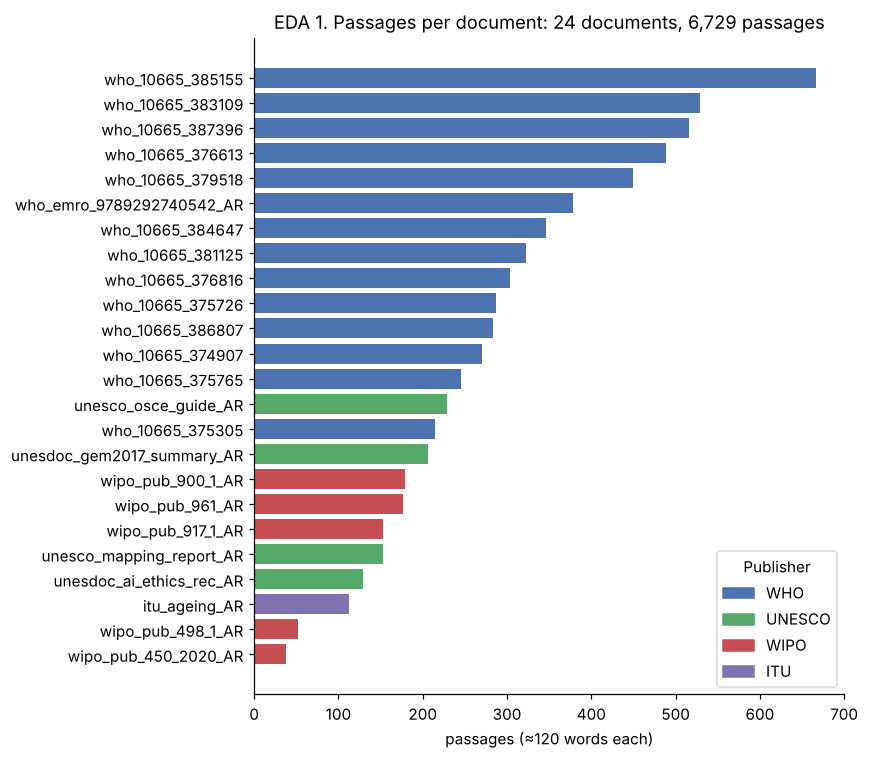

In [6]:
overview = (P.groupby("publisher_group")
              .agg(documents=("document_id", "nunique"), passages=("passage_id", "count"))
              .join(accepted.assign(publisher_group=accepted.document_id.map(
                  lambda d: "WHO" if d.startswith("who") else "UNESCO" if "unes" in d else "WIPO" if d.startswith("wipo") else "ITU"))
                    .groupby("publisher_group")[["pdf_pages", "kept_pages", "kept_words"]].sum()))
overview["share_of_passages"] = (overview.passages / overview.passages.sum()).map("{:.0%}".format)
overview.loc["Total"] = [overview.documents.sum(), overview.passages.sum(), overview.pdf_pages.sum(),
                         overview.kept_pages.sum(), overview.kept_words.sum(), "100%"]
display(overview)

COLORS = {"WHO": "#4C72B0", "UNESCO": "#55A868", "WIPO": "#C44E52", "ITU": "#8172B2"}
per_doc = P.groupby(["document_id", "publisher_group"]).size().reset_index(name="passages").sort_values("passages")
fig, ax = plt.subplots(figsize=(8, 7))
from matplotlib.patches import Patch
ax.barh(per_doc.document_id, per_doc.passages, color=per_doc.publisher_group.map(COLORS))
ax.legend(handles=[Patch(color=c, label=g) for g, c in COLORS.items()], title="Publisher", loc="lower right")
ax.set_xlabel("passages (≈120 words each)")
ax.set_title("EDA 1. Passages per document: 24 documents, 6,729 passages")
plt.tight_layout(); plt.show()

**Reading.** The corpus clears the 5,000-passage requirement with 1,729 to spare, but it is **unbalanced**: WHO guidance provides 79 % of passages. A retrieval model can look good on average by doing well on WHO only, so Milestone 2 reports metrics per publisher, and the evaluation questions were allocated per document by the square root of its size (7–12 questions each) rather than in proportion to it.

### EDA 2 — Data quality: screening, damaged words, missing text, duplicates

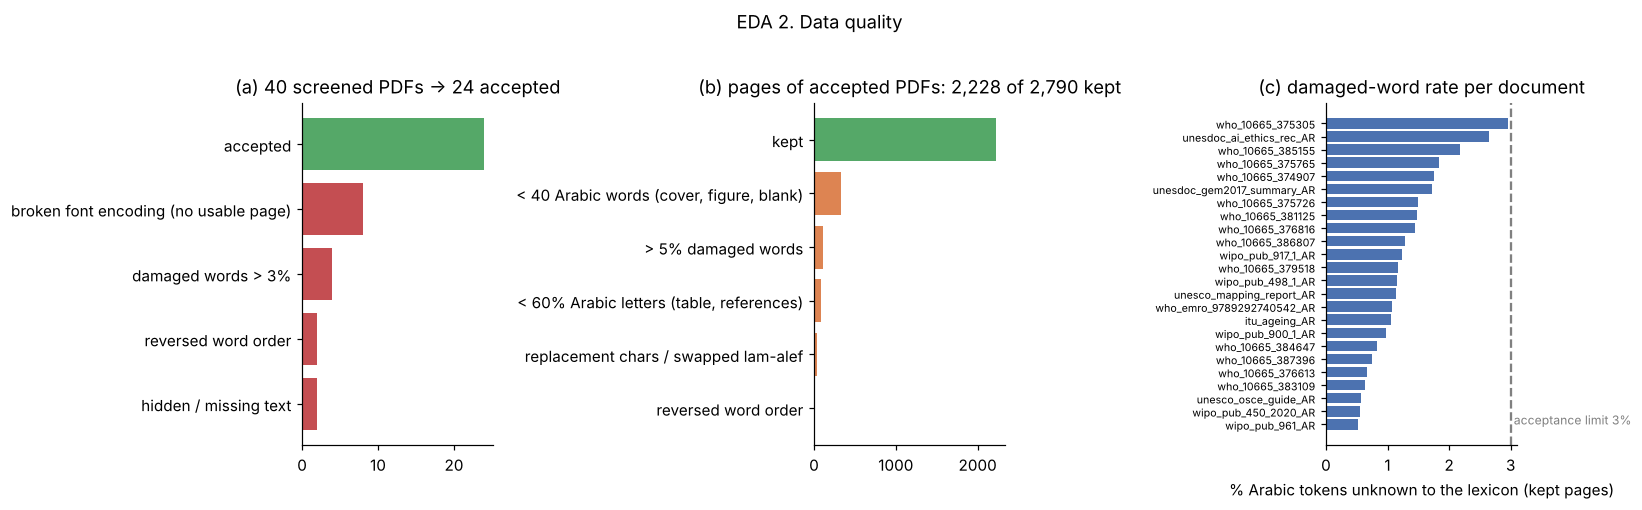

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
# (a) document screening
rej = manifest[manifest.screening_status == "REJECT"].reject_reason.fillna("")
reason = rej.map(lambda s: "broken font encoding (no usable page)" if "no page passes" in s else
                 "damaged words > 3%" if "damaged" in s else "reversed word order" if "reversed" in s else
                 "hidden / missing text" if "pypdf" in s else "other").value_counts()
axes[0].barh(["accepted"] + list(reason.index), [len(accepted)] + list(reason.values),
             color=["#55A868"] + ["#C44E52"] * len(reason))
axes[0].set_title("(a) 40 screened PDFs → 24 accepted"); axes[0].invert_yaxis()
# (b) page-level reasons inside accepted documents
s = scores[scores.file.isin(accepted.file)].copy()
def page_reason(r):
    if r.keep: return "kept"
    if r.ar_tokens < 40: return "< 40 Arabic words (cover, figure, blank)"
    if r.ar_share < 0.6: return "< 60% Arabic letters (table, references)"
    if r.reversed: return "reversed word order"
    if (r.oov or 0) > 0.05: return "> 5% damaged words"
    return "replacement chars / swapped lam-alef"
s["reason"] = s.apply(page_reason, axis=1)
rc = s.reason.value_counts()
rc = rc[rc > 0]
axes[1].barh(rc.index, rc.values, color=["#55A868" if i == "kept" else "#DD8452" for i in rc.index])
axes[1].set_title(f"(b) pages of accepted PDFs: {rc['kept']:,} of {len(s):,} kept"); axes[1].invert_yaxis()
# (c) damaged-word rate per accepted document
d = accepted.sort_values("damaged_word_rate_kept")
axes[2].barh(d.document_id, d.damaged_word_rate_kept * 100, color="#4C72B0")
axes[2].axvline(3, color="grey", ls="--"); axes[2].text(3.05, 0, "acceptance limit 3%", color="grey", fontsize=8)
axes[2].set_xlabel("% Arabic tokens unknown to the lexicon (kept pages)")
axes[2].set_title("(c) damaged-word rate per document"); axes[2].tick_params(axis="y", labelsize=7)
fig.suptitle("EDA 2. Data quality", y=1.02); plt.tight_layout(); plt.show()

In [8]:
def near_duplicates(texts, ids, n=8, step=4, min_shared=8):
    """Passages sharing >= min_shared n-word shingles with another passage (boilerplate, repeated boxes)."""
    sh = collections.defaultdict(set)
    for pid, t in zip(ids, texts):
        w = re.sub(r"[^ء-ي ]", " ", t).split()
        for i in range(0, max(0, len(w) - n), step):
            sh[" ".join(w[i:i + n])].add(pid)
    c = collections.Counter()
    for s_ids in sh.values():
        if len(s_ids) > 1:
            for pid in s_ids:
                c[pid] += 1
    return {pid for pid, k in c.items() if k >= min_shared}

quality = pd.Series({
    "PDF pages in accepted documents": len(s),
    "empty pages (no text layer content)": int((s.words == 0).sum()),
    "pages dropped by the screen": int((~s.keep).sum()),
    "passages": len(P),
    "empty passages after cleaning": int((P.clean_text.str.strip() == "").sum()),
    "exact duplicate passages (v1)": int(v1.exact_dup_of.notna().sum()),
    "near-duplicate passages, before cleaning": len(near_duplicates(P.text_v1, P.passage_id)),
    "near-duplicate passages, after cleaning": len(near_duplicates(P.clean_text, P.passage_id)),
    "Persian/Urdu look-alike letters (ی ھ ک)": int(P.text_v1.str.count("[یھک]").sum()),
    "leaked font glyph names (/uni0627, two.fitted)": int(P.text_v1.map(lambda t: len(bp.GLYPH_NAME.findall(t))).sum()),
    "passages containing glyph names": int(P.text_v1.str.contains(bp.GLYPH_NAME).sum()),
})
quality.to_frame("count")

,count
PDF pages in accepted documents,2790
empty pages (no text layer content),47
pages dropped by the screen,562
passages,6729
empty passages after cleaning,0
exact duplicate passages (v1),3
"near-duplicate passages, before cleaning",335
"near-duplicate passages, after cleaning",297
Persian/Urdu look-alike letters (ی ھ ک),4117
"leaked font glyph names (/uni0627, two.fitted)",2899


**Reading.** (a) Most rejected PDFs failed completely — their fonts map glyphs to wrong or private code points, so no page passed. (b) Inside accepted PDFs, a fifth of pages are dropped, mostly covers, figures, tables and reference lists rather than damaged prose. (c) Accepted documents keep 0.5–3 % unknown tokens; part of that is names and rare terms, not damage. There are no missing values in the passage table and only 3 exact duplicates (a repeated back cover); near-duplicates (shared boilerplate) fall from 335 to 297 after the cleaning in §5. Two problems were invisible to the page screen because its lexicon check only counts Arabic-letter tokens: **4,117 Persian look-alike letters** (U+06CC, U+06BE) in three documents, which look identical on the page but never match an Arabic query, and **2,899 leaked font glyph names** (`/uni0627`, `two.fitted`) in 31 passages, all from chart labels. Each led to a preprocessing step.

### EDA 3 — Text characteristics: page, passage and sentence length

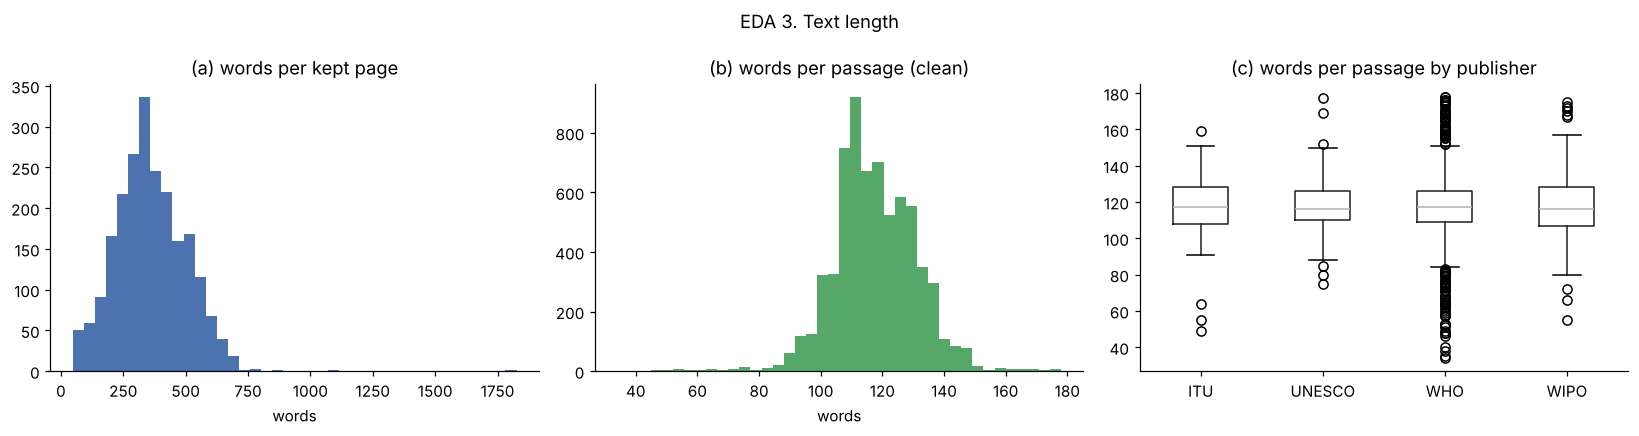

,count,mean,std,min,25%,50%,75%,max
words_clean,6729.0,117.4,13.8,34.0,109.0,116.0,126.0,178.0
chars_clean,6729.0,750.4,133.7,211.0,681.0,741.0,807.0,3263.0
sentences,6729.0,5.8,2.7,1.0,4.0,6.0,7.0,31.0


In [9]:
P["words_clean"] = P.clean_text.str.split().map(len)
P["chars_clean"] = P.clean_text.str.len()
P["sentences"] = P.clean_text.map(lambda t: len(bp.sentences(t)))
kept_s = s[s.keep]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(kept_s.words, bins=40, color="#4C72B0"); axes[0].set_title("(a) words per kept page"); axes[0].set_xlabel("words")
axes[1].hist(P.words_clean, bins=40, color="#55A868"); axes[1].set_title("(b) words per passage (clean)"); axes[1].set_xlabel("words")
P.boxplot(column="words_clean", by="publisher_group", ax=axes[2], grid=False)
axes[2].set_title("(c) words per passage by publisher"); axes[2].set_xlabel(""); fig.suptitle("EDA 3. Text length")
plt.tight_layout(); plt.show()
P[["words_clean", "chars_clean", "sentences"]].describe().round(1).T

**Reading.** Kept pages hold 360 words on average (median 350); 13 dense pages exceed 700 words (maximum 1,826). That spread is why pages are split into ~120-word passages: short enough to fit embedding-model input limits and to cite a single page precisely, long enough to hold a complete answer. Clean passages have a median of 116 words and about 6 sentences; the short outliers (down to 34 words) are passages that lost a running header or chart residue during cleaning.

### EDA 4 — Arabic-specific characteristics: script variants, spelling, code-switching, dialect

In [10]:
raw_kept = pd.Series({(f, p): raw_pages[f][p - 1] for f in raw_pages for p in kept_pages[f]})
text_all = " ".join(P.text_v1)
words_all = re.findall(r"[ء-يیھک]+", bp.DIACRITICS.sub("", text_all))
arabic_letters = len(bp.ARABIC_LETTER.findall(text_all))
dialect_markers = ["مش", "عايز", "عاوز", "إزاي", "ازاي", "هيك", "شلون", "بدي", "ليش", "دلوقتي", "كده"]
feat = pd.Series({
    "presentation-form characters in raw pypdf output (fixed by NFKC)": int(raw_kept.str.count(bp.PRESENTATION_FORMS.pattern).sum()),
    "tatweel (kashida) in raw output": int(raw_kept.str.count("ـ").sum()),
    "diacritics per 100 Arabic letters": round(100 * len(bp.DIACRITICS.findall(text_all)) / arabic_letters, 2),
    "words starting with أ / إ / آ": sum(w[0] in "أإآ" for w in words_all),
    "words starting with bare ا (incl. ال)": sum(w[0] == "ا" for w in words_all),
    "word-final ى (alef maqsura)": sum(w.endswith("ى") for w in words_all),
    "word-final ي (ya)": sum(w.endswith("ي") for w in words_all),
    "word-final ة (ta marbuta)": sum(w.endswith("ة") for w in words_all),
    "word-final ه (ha)": sum(w.endswith("ه") for w in words_all),
    "Persian look-alike letters (ی ھ ک)": len(re.findall("[یھک]", text_all)),
    "Western digits 0-9": len(re.findall(r"[0-9]", text_all)),
    "Arabic-Indic digits ٠-٩": len(re.findall(r"[٠-٩]", text_all)),
    "Latin-script tokens (code-switching)": len(re.findall(r"\b[A-Za-z][A-Za-z\-]+\b", text_all)),
    "colloquial (dialect) marker words": sum(w in dialect_markers for w in text_all.split()),
})
display(feat.to_frame("count"))
latin = collections.Counter(re.findall(r"\b[A-Z][A-Z0-9\-]{1,9}\b", text_all)).most_common(12)
print("most frequent Latin acronyms:", ", ".join(f"{a} ({n})" for a, n in latin))
share_latin = P.text_v1.map(lambda t: len(bp.LATIN.findall(t)) / max(1, len(t.replace(" ", ""))))
print(f"passages with > 5% Latin characters: {(share_latin > 0.05).mean():.1%}")

,count
presentation-form characters in raw pypdf output (fixed by NFKC),44885.00
tatweel (kashida) in raw output,126044.00
diacritics per 100 Arabic letters,1.28
words starting with أ / إ / آ,60072.00
words starting with bare ا (incl. ال),266764.00
word-final ى (alef maqsura),32398.00
word-final ي (ya),63666.00
word-final ة (ta marbuta),151947.00
word-final ه (ha),11962.00
Persian look-alike letters (ی ھ ک),4117.00


most frequent Latin acronyms: WHO (186), IGO (43), CC (36), ISBN (33), IP (31), BY-NC-SA (30), PANORAMATM (25), TB (24), S- (22), DHIS2 (19), USB (19), CD (18)
passages with > 5% Latin characters: 7.4%


**Reading.** The text is formal **Modern Standard Arabic**: colloquial markers are essentially absent, so no dialect handling is needed in the documents (questions may still be informal). The main variation is **orthographic and technical**: hamza forms of alef, ى/ي and ة/ه at word end, optional diacritics (present on some words only), tatweel used for justification, presentation forms, and Persian look-alike letters. Users type these inconsistently, so a lexical retriever needs a normalised view. Code-switching is limited to acronyms (WHO, SDG, TB…) and reference lists; numbers mostly use Western digits.

### EDA 5 — Task-specific analysis for RAG: topic coverage, vocabulary, answer availability

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
P["retrieval_text"] = P.clean_text.map(bp.normalize_for_retrieval)
P["tfidf_tokens"] = P.clean_text.map(bp.tfidf_tokens)
docs = P.groupby("document_id").tfidf_tokens.sum()
vec = TfidfVectorizer(analyzer=lambda x: x, min_df=1, max_df=0.5, sublinear_tf=True)
X = vec.fit_transform(docs.values)
terms = np.array(vec.get_feature_names_out())
top = {d: " · ".join(terms[np.argsort(-X[i].toarray()[0])[:8]]) for i, d in enumerate(docs.index)}
titles = accepted.set_index("document_id").title
display(pd.DataFrame({"title": titles.reindex(docs.index).str[:55], "top TF-IDF stems": pd.Series(top)}))

tok = [t for ts in P.tfidf_tokens for t in ts]
ret = " ".join(P.retrieval_text).split()
print(f"retrieval view: {len(ret):,} tokens, {len(set(ret)):,} types | TF-IDF view (stop words removed, stemmed): "
      f"{len(tok):,} tokens, {len(set(tok)):,} types")
print(f"passages containing a number (candidate numeric questions): {P.clean_text.str.contains(r'[0-9٠-٩]').mean():.0%}")
print("existing questions/answers in the source documents: 0 → evaluation set of ~300 questions in preparation (§7)")

,title,top TF-IDF stems
itu_ageing_AR,Ageing in a digital world: from vulnerable to valuable,شيخوخ · itu · مسن · خه · ageing · تنقلي · لكبار · covid
unesco_mapping_report_AR,SDG 4 policy mapping in Arab States,لالال · اعدادي · عمنعمنعم · ابتدايي · نعمتتضم · تقييمملاحظهالتقييمالتقييمالتقييم · سلطن · عمجزييانعم
unesco_osce_guide_AR,Addressing anti-Semitism through education: guidelines,معادا · يهود · يهودي · معادي · لمعادا · سامي · هولوكوست · قوالب
unesdoc_ai_ethics_rec_AR,Recommendation on the Ethics of Artificial Intelligence,بلذكاء · ذكاء · اصطناعي · يه · ايكولوجي · بلبيان · باخلاقي · شاطر
unesdoc_gem2017_summary_AR,Accountability in education: GEM Report 2017/8 summary,معلمي · بامج · وليء · قرايي · كبي · صحراء · قواني · لتحسي
who_10665_374907,تقدير المخاطر,ستخدا · مزارع · وتوكلف · لضبط · خزان · اسا · رذاذ · دوامي
who_10665_375305,الدليل التشغيلي لمنظمة الصحة العالمية بشأن السل: الوحدة,فروس · غر · متعايشن · مصابن · تشخيي · مخالطن · سيني · بن
who_10665_375726,إجراءات التشغيل الموحدة لإدارة سلسلة الإمداد بالمنتجات,تخليص · مهمهالتعليماتالمسووليهالمراجع · كرت · كرتون · مخازن · جموعي · شحن · متبرع
who_10665_375765,رعاية مقدمي الرعاية: دليل لوضع وتنفيذ برامج الصحة والسل,مهنيت · occupational · زنجبار · br · عداوي · healthwise · ايدز · ilo
who_10665_376613,الإنذار المبكّر والاستجابة في حالات الطوارئ: دليل عملي,امته · لانذار · اسبوعي · ترصد · فاشي · تنبيه · فرضي · اعتلال


retrieval view: 790,018 tokens, 52,316 types | TF-IDF view (stop words removed, stemmed): 618,762 tokens, 21,399 types
passages containing a number (candidate numeric questions): 80%
existing questions/answers in the source documents: 0 → evaluation set of ~300 questions in preparation (§7)


**Reading.** Each document has a distinct vocabulary — tuberculosis (`سل`, `جرثومي`), tobacco (`تبغ`, `نيكوت`), nursing (`تمريض`, `كادر`), emergency alerts (`انذار`, `ترصد`), patents and trademarks (`براء`, `اختراع`), ageing (`شيخوخ`, `مسن`) — so retrieval must first find the right document and then the right page; several WHO documents share primary-care and child-health vocabulary, which is where retrieval errors are most likely. The distinctive terms also **expose each document's remaining extraction errors**, because a damaged form is rare and therefore scores high: dropped letters (`بامج` for برامج, `مصابن` for مصابين), the lost alef of بال (`بلذكاء`), table cells glued together (`عمنعمنعم`), and URL fragments (`bit · ly`). These are the "few damaged words" the instructor accepted; they matter most for lexical retrieval (RQ2). Normalisation and light stemming cut the vocabulary from 52,316 to 21,399 types. Most passages (80 %) contain numbers, so numeric questions are realistic. The PDFs contain **no question-answer pairs**, so the evaluation set is built separately (§7).

## 5. Preprocessing pipeline

Three views are produced for every passage. The **clean view** is what a reader sees and what answers are generated from; nothing in it is removed unless it is extraction noise. The **retrieval view** and **TF-IDF view** are only used for matching. Passage boundaries were fixed after steps 1–2 so that passage IDs never change.

| # | Operation | Applied to | Why (evidence) | Guard against information loss |
|---|---|---|---|---|
| 1 | Unicode **NFKC** normalisation | page text | 44,885 presentation-form characters in raw pypdf output (EDA 4) | only compatibility characters change; letters already standard stay |
| 2 | **Tatweel** removal | page text | about 126,000 kashida characters split identical words (EDA 4) | kashida carries no meaning |
| 3 | **Boilerplate removal** (running headers, side tabs, page-number lines) | clean | headers repeated on 20–98 % of a document's pages, often glued to body text | a line must repeat on ≥ 20 % of the document's pages and have ≥ 2 words; body sentences do not repeat that often |
| 4 | **Glyph-name artefact removal** (`/uni0627`, `two.fitted`) | clean | 2,899 leaked font glyph names in 31 passages, all from chart labels (EDA 2, EDA 5) | pattern only matches glyph-name syntax, never words |
| 5 | **Letter unification** ی ھ ک → ي/ى ه ك | clean | 4,117 Persian look-alike letters (EDA 2) | follows the drawn glyph: word-final ی → ى |
| 6 | **Whitespace & diacritic repair** | clean | diacritics detached by extraction (`المُعم َّق`) | only removes a space before a diacritic |
| 7 | **Glued-word splitting** | clean | words joined at line breaks (`التسجيلفي`) | only tokens unknown to the lexicon; both parts must be frequent words (precision audited in §5.3) |
| 8 | **Orthographic normalisation** (diacritics, أإآ→ا, ى→ي, ة→ه, digits, punctuation) | retrieval view | spelling variants in EDA 4 | clean text keeps the original spelling |
| 9 | **Tokenisation, stop-word removal, light stemming** (NLTK Arabic stop words, ARLSTem) | TF-IDF view | vocabulary reduction (EDA 5) | never applied to clean or embedding input |
| 10 | **Sentence segmentation** | clean | sentence counts (EDA 3); later for answer extraction | segmentation only, no deletion |

In [12]:
ops = ["boilerplate_words", "glyph_names_removed", "letters_unified", "diacritics_reattached", "glued_split"]
changed = pd.DataFrame({"items changed": P[ops].sum().astype(int), "passages affected": (P[ops] > 0).sum()})
changed.index = ["3 boilerplate words removed", "4 glyph names removed", "5 letters unified",
                 "6 diacritics re-attached", "7 glued words split"]
raw_total = pd.DataFrame({"items changed": [int(feat.iloc[0]), int(feat.iloc[1])], "passages affected": ["page level"] * 2},
                         index=["1 presentation forms normalised", "2 tatweel removed"])
display(pd.concat([raw_total, changed]))
before_w, after_w = P.text_v1.str.split().map(len).sum(), P.words_clean.sum()
print(f"words: {before_w:,} before cleaning → {after_w:,} after ({(before_w - after_w) / before_w:.1%} fewer: "
      f"boilerplate and glyph names removed, partly offset by split words)")

,items changed,passages affected
1 presentation forms normalised,44885,page level
2 tatweel removed,126044,page level
3 boilerplate words removed,12929,1991
4 glyph names removed,2899,31
5 letters unified,4117,117
6 diacritics re-attached,365,223
7 glued words split,821,634


words: 802,922 before cleaning → 789,940 after (1.6% fewer: boilerplate and glyph names removed, partly offset by split words)


### 5.1 Before / after examples (real passages from the corpus)

In [13]:
def page_snippet(file, page, find, width=110):
    raw = raw_pages[file][page - 1]
    i = max(0, raw.find(find) - 10) if isinstance(find, str) else find
    return raw[i:i + width]

def show(title, before, after, note=""):
    print(f"■ {title}")
    print("  BEFORE:", before.replace("\n", " ⏎ "))
    print("  AFTER :", after.replace("\n", " ⏎ "))
    if note:
        print("  NOTE  :", note)
    print()

# 1 NFKC: presentation forms → standard letters (WHO 383109, page 1)
f = "bayan_who_10665_383109.pdf"
pg = next(i for i, t in enumerate(raw_pages[f]) if bp.PRESENTATION_FORMS.search(t)) + 1
seg = page_snippet(f, pg, bp.PRESENTATION_FORMS.search(raw_pages[f][pg - 1]).start(), 70)
show(f"1. NFKC normalisation — {f[6:-4]} p.{pg}", " ".join(f"U+{ord(c):04X}" for c in seg[:6]) + " …  " + seg,
     " ".join(f"U+{ord(c):04X}" for c in bp.nfkc(seg)[:6]) + " …  " + bp.nfkc(seg),
     "same visible text; presentation forms become letters. The font's Farsi-yeh glyphs become Persian ی "
     "(e.g. 'التقییم'), which step 5 then maps to Arabic ي")

# 2 Tatweel removal (WHO 385155)
f = "bayan_who_10665_385155.pdf"
pg = next(i for i, t in enumerate(raw_pages[f]) if t.count("ـ") > 50) + 1
seg = page_snippet(f, pg, raw_pages[f][pg - 1].find("ـ") - 30, 120)
show(f"2. Tatweel removal — {f[6:-4]} p.{pg}", seg, bp.page_text(seg), "'المنــظمات' becomes 'المنظمات'")

byid = P.set_index("passage_id")

# 3 Boilerplate removal (WHO EMRO, page 80)
r = byid.loc["who_emro_9789292740542_AR_p0080_0"]
show("3. Boilerplate removal — who_emro_9789292740542_AR p.80", r.text_v1[:230], r.clean_text[:170],
     "running header glued to the body ('…في عاممرتَسَم الصحة…') and page numbers removed")

# 4 Glyph-name artefacts (WHO EMRO, page 33: chart labels)
r = byid.loc["who_emro_9789292740542_AR_p0033_0"]
show("4. Glyph-name artefact removal — who_emro_9789292740542_AR p.33", r.text_v1[:260], r.clean_text[:200],
     f"{r.glyph_names_removed} glyph names removed from this passage; the Arabic prose after the chart is kept")

# 5+6 Letter unification and diacritic re-attachment (WHO 383109)
r = byid.loc["who_10665_383109_p0033_2"]
show("5 + 6. Letter unification and diacritic repair — who_10665_383109 p.33", r.text_v1[:200], r.clean_text[:200],
     "'التقییم' (Persian ی) → 'التقييم'; 'المُعم َّق' → 'المُعمَّق'")

# 7 Glued-word splitting (WIPO 900.1, page 27)
r = byid.loc["wipo_pub_900_1_AR_p0027_0"]
i, j = r.text_v1.find("التسجيلفي"), r.clean_text.find("التسجيل في")
show("7. Glued-word splitting — wipo_pub_900_1_AR p.27", r.text_v1[i - 60:i + 40], r.clean_text[j - 60:j + 41])

# 8+9 Retrieval and TF-IDF views (WIPO 917.1, page 36)
r = P[P.passage_id.str.startswith("wipo_pub_917_1_AR_p0036")].iloc[0]
show("8. Orthographic normalisation (retrieval view) — wipo_pub_917_1_AR p.36", r.clean_text[:160], r.retrieval_text[:160],
     "الحماية→الحمايه, إيداع→ايداع, أو→او; punctuation removed")
show("9. Tokenisation, stop words, light stemming (TF-IDF view)", r.retrieval_text[:120], " ".join(r.tfidf_tokens[:18]),
     "'التي', 'من', 'في' removed; 'الحمايه'→'حماي', 'المعيار'→'معيار'")

# 10 Sentence segmentation
sents = bp.sentences(r.clean_text)
show("10. Sentence segmentation", r.clean_text[:160], " ‖ ".join(sents[:3])[:200], f"{len(sents)} sentences in this passage")

■ 1. NFKC normalisation — who_10665_383109 p.1
  BEFORE: U+FEB7 U+FE8E U+062F U+0627 U+062A U+0020 …  ﺷﺎدات ﺑﺷﺄن اﻟﺗﻘﯾﯾم اﻟﻣﺗﻣرﻛز ﻋﻠﻰ ⏎ اﻟﺷﺧص وﻣﺳﺎرات اﻟرﻋﺎﯾﺔ اﻷوﻟﯾﺔ ⏎ اﻟطﺑﻌﺔ اﻟ
  AFTER : U+0634 U+0627 U+062F U+0627 U+062A U+0020 …  شادات بشأن التقییم المتمركز على ⏎ الشخص ومسارات الرعایة الأولیة ⏎ الطبعة ال
  NOTE  : same visible text; presentation forms become letters. The font's Farsi-yeh glyphs become Persian ی (e.g. 'التقییم'), which step 5 then maps to Arabic ي

■ 2. Tatweel removal — who_10665_385155 p.4
  BEFORE:  منظمة الصحة العالمُية© ⏎   لفائــدة المنــظمات الحكوميــة 3.0 بعــض الحقــوق محفوظــة. هــذا المصنــف متــاح بمقــتضى ترخ
  AFTER :  منظمة الصحة العالمُية© ⏎   لفائدة المنظمات الحكومية 3.0 بعض الحقوق محفوظة. هذا المصنف متاح بمقتضى ترخ
  NOTE  : 'المنــظمات' becomes 'المنظمات'

■ 3. Boilerplate removal — who_emro_9789292740542_AR p.80
  BEFORE: 6061 2019 نظرة عامة على الوضع الصحي في الإقليم في عاممرتَسَم الصحة والعافية لإقليم شرق المتوسط وتتخذ بلدان الإقليم تدابير للتصدي

### 5.2 What the pipeline deliberately does **not** do
- **No stop-word removal, stemming, digit or punctuation removal on the clean text.** Answers often hinge on function words ("لا"، "إلا"), numbers and dates; these operations run only in the TF-IDF view.
- **No diacritic removal on the clean text.** Diacritics disambiguate (e.g. `يُطبَّق`); they are removed only for matching.
- **No reordering of words** where extraction moved a bold phrase or number within a line: there is no reliable rule, and a wrong guess would corrupt the evidence. Such passages remain retrievable by their words; the issue is recorded as a known limitation.
- **No LLM or OCR "repair".** Rewriting text would make the evidence differ from the PDF page that we cite.

### 5.3 Glued-word splitting — precision check
A random sample of splits is printed so that the rule can be audited.

In [14]:
import random
random.seed(0)
samples = []
for t in P.text_v1.sample(800, random_state=0):
    _, ch = bp.split_glued(bp.repair_spacing(bp.unify_letters(t)[0])[0])
    samples += ch
for before, after in random.sample(samples, min(15, len(samples))):
    print(f"{before:>22}  →  {after}")

            الكشفاتفاق  →  الكشف اتفاق
      والمناقشةالمجتمع  →  والمناقشة المجتمع
              التنفسلا  →  التنفس لا
       الملكيةالصناعية  →  الملكية الصناعية
           التعليمملخص  →  التعليم ملخص
        الصحيةمستشفيات  →  الصحية مستشفيات
          العالميةنسبة  →  العالمية نسبة
              التنفسلا  →  التنفس لا
             مثالأسئلة  →  مثال أسئلة
              الفصلكما  →  الفصل كما
            منالنفايات  →  من النفايات
            منالرئيسية  →  من الرئيسية
         المنظمةبيانات  →  المنظمة بيانات
            عنهاالمادة  →  عنها المادة
          ينبغيالإقرار  →  ينبغي الإقرار


In this sample 14 of the 15 splits are correct; the error is the product name `روكفور` (Roquefort) split into two frequent words. Splitting is therefore kept in the clean view (it fixes far more than it breaks) and its effect on retrieval is measured as part of RQ2.

## 6. Output of the pipeline

In [15]:
P["tfidf_text"] = P.tfidf_tokens.map(" ".join)
cols = ["passage_id", "document_id", "file", "pdf_page", "publisher", "publisher_group", "text_v1", "clean_text",
        "retrieval_text", "tfidf_text", "words_clean", "sentences"] + ops
P[cols].to_parquet(os.path.join(OUT, "passages_v1_processed.parquet"), index=False)
print(f"saved {len(P)} passages → data/processed/passages_v1_processed.parquet")
P[["passage_id", "pdf_page", "clean_text", "retrieval_text", "tfidf_text"]].head(3)

saved 6729 passages → data/processed/passages_v1_processed.parquet


,passage_id,pdf_page,clean_text,retrieval_text,tfidf_text
0,itu_ageing_AR_p0004_0,4,".يرجى مراعاة الجوانب البيئية قبل طباعة هذا التقرير شكر وتقدير صيغ تقرير ""الشيخوخة في عالم رقمي - من التأثر إلى التأث...",يرجي مراعاه الجوانب البيييه قبل طباعه هذا التقرير شكر وتقدير صيغ تقرير الشيخوخه في عالم رقمي من التاثر الي التاثير ب...,رجي مراعا جوانب بييي طباع تقرير شكر قدير صيغ قرير شيخوخ عالم رقمي تاثر تاثير بقلم سيد ماري كاريلو مدير عملي موسس خبي...
1,itu_ageing_AR_p0004_1,4,بأي حال من الأحوال التعبير عن أي رأي من جانب الاتحاد الدولي للاتصالات فيما يتعلق بالوضع القانوني لأيٍّ من البلدان أو...,باي حال من الاحوال التعبير عن اي راي من جانب الاتحاد الدولي للاتصالات فيما يتعلق بالوضع القانوني لاي من البلدان او ا...,باي حال حول تعبير جانب تحد دولي اتصال تعلق وضع قانوني لاي بلد اقليم مدن مناطق لسلط تعلق بتعي حدود خوم اشره شرك منتج ...
2,itu_ageing_AR_p0004_2,4,والاستنتاجات المعرب عنها في هذا المنشور لا تعبر بالضرورة عن وجهات نظر الاتحاد الدولي للاتصالات أو أعضائه. وفي حين كا...,والاستنتاجات المعرب عنها في هذا المنشور لا تعبر بالضروره عن وجهات نظر الاتحاد الدولي للاتصالات او اعضايه وفي حين كان...,استنتاج معرب عنه منشور عبر ضرور جه نظر تحد دولي اتصال عضي وفي كان روابط الكتروني مراجع خارجي صله وارد تقرير ساري صلا...


## 7. Next steps (Milestone 2)
- **Evaluation set.** ~300 Arabic questions (200 single-passage, 30 multi-passage, 70 unanswerable), allocated across all 24 documents, written by a *different* AI model from the corpus alone, then verified by the team against the PDF pages; split 30 % dev / 70 % test before any tuning.
- **Representations.** TF-IDF and BM25 on the TF-IDF view; a multilingual and an Arabic sentence-embedding model on the clean view.
- **Experiments.** Representation comparison (RQ1); normalisation on/off and boilerplate removal on/off (RQ2); passage size 120 vs 60 words; abstention threshold (RQ3).
- **Metrics.** Recall@5, MRR@10, nDCG@10, answer token-F1 / exact match, citation accuracy, abstention precision/recall.

### Known limitations
- Extraction can move a bold phrase or a number within its line (seen in WIPO and WHO pages); words are intact but order is local-scrambled.
- The damaged-word measure counts names and rare terms as "damaged", and cannot see non-Arabic-letter noise (Persian look-alike letters, glyph names); steps 4–5 now handle the two cases found.
- Some extraction damage cannot be repaired safely and remains in the clean text: dropped letters (`بامج`), the lost alef of بال (`بلذكاء`), and table cells glued together.
- 79 % of passages come from WHO; results are reported per publisher.
- The ARLSTem light stemmer sometimes over-strips (e.g. `وتقدير` → `قدير`); stemming is therefore an experimental condition, not a default.

## 8. References
- Source documents: see `data/corpus_v1/manifest_v1.csv` (title, publisher, URL, licence, SHA-256 for each of the 40 screened PDFs) — WHO IRIS (iris.who.int), WHO EMRO, UNESDOC (unesdoc.unesco.org), UNESCO Beirut, OSCE/ODIHR, WIPO (wipo.int), ITU (itu.int).
- pypdf 6.21.2 — https://pypdf.readthedocs.io · PyMuPDF — https://pymupdf.readthedocs.io (used only to detect hidden/off-page text).
- Speer, R. *wordfreq* 3.1 — https://github.com/rspeer/wordfreq (Arabic word-frequency lexicon for the damaged-word check).
- Bird, S., Klein, E., Loper, E. *NLTK* — Arabic stop-word list; Abainia, K., Ouamour, S., Sayoud, H. (2017). A novel robust Arabic light stemmer (ARLSTem). *Journal of Experimental & Theoretical Artificial Intelligence* 29(3).
- Pedregosa et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR* 12.
- Unicode Standard Annex #15, Unicode Normalization Forms (NFKC).

## 9. Team contributions
| Member | Contribution |
|---|---|
| *[Name]* | *[e.g. problem definition, dataset screening]* |
| *[Name]* | *[e.g. EDA]* |
| *[Name]* | *[e.g. preprocessing pipeline, documentation]* |